# Exploring the Dash *et al* dataset

This data was generated in [Quantifiable predictive features define epitope specific T cell  receptor repertoires](https://doi.org/10.1038/nature22383) and further analysed in [Measures of epitope binding degeneracy from T cell receptor repertoires](https://www.pnas.org/doi/abs/10.1073/pnas.2213264120). In this notebook we explore the dataset and re-create some of the analysis done in other works.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from matplotlib.axes import Axes
from pyxdameraulevenshtein import damerau_levenshtein_distance
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

2025-12-17 17:43:50.029913: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
def plot_umap(umap: np.ndarray, clusters: np.ndarray, title: str | None = None, ax: Axes | None = None) -> Axes:
    ax = sns.scatterplot(
        x=umap[clusters == 'None', 0],
        y=umap[clusters == 'None', 1],
        color='grey',
        alpha=0.55,
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters != 'None', 0],
        y=umap[clusters != 'None', 1],
        hue=clusters[clusters != 'None'],
        alpha=0.65,
        ax=ax,
    )

    ax.set_title(title)
    ax.legend(title='Cluster')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    return ax

In [3]:
dash = pd.read_csv('../data/external/dash_human.csv')
dash.index.name = 'id'
dash = dash.reset_index()
dash['id'] = 'dash_' + dash['id'].astype(str)

In [4]:
dash = dash.dropna()

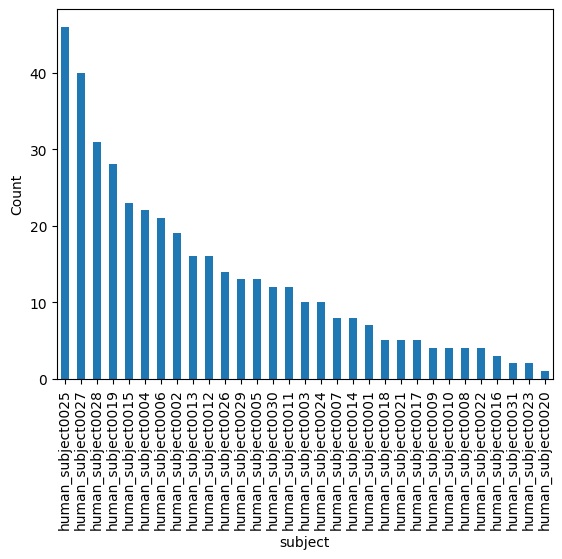

In [5]:
dash['subject'].value_counts().plot.bar()

plt.ylabel('Count')

plt.show()

In [6]:
dash.value_counts('epitope')

epitope
M1      249
BMLF     92
pp65     67
Name: count, dtype: int64

## BMLF Epitope Analysis

In [7]:
dash_bmlf = dash.query("epitope == 'BMLF'").copy()

In [8]:
num_tcrs = len(dash_bmlf)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_a_aa'], dash.iloc[j]['cdr3_a_aa']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_b_aa'], dash.iloc[j]['cdr3_b_aa']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [9]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [10]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [11]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [12]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [13]:
unique_subjects = sorted(dash_bmlf['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_bmlf['subject'].to_numpy()[new_order]])

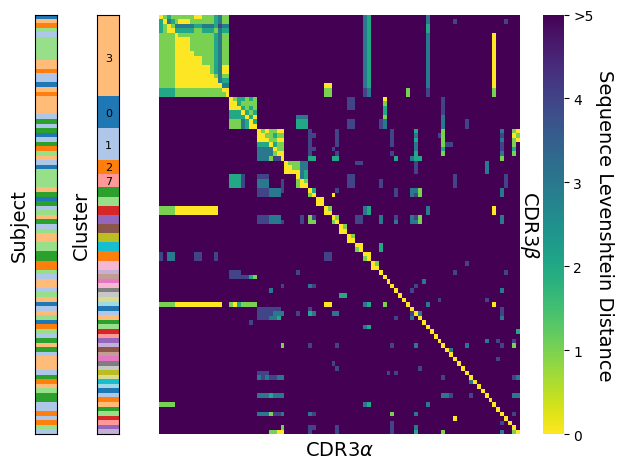

In [14]:
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 3

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

ax1.imshow(subject_colours, aspect='auto')

ax1.set_ylabel('Subject', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

ax2.imshow(cluster_colours, aspect='auto')

ax2.set_ylabel('Cluster', fontsize=14)
ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

accumulation = 0
for cluster in cluster_order:
    cluster_size = cluster_counts[cluster]

    if cluster_size >= MIN_CLUSTER_SIZE:
        position = cluster_counts[cluster] // 2 + accumulation
        ax2.text(
            x=0.025,
            y=position,
            s=str(cluster),
            va='center',
            ha='center',
            fontsize=8,
        )

    accumulation += cluster_size

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax3
)

ax3.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax3.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax3.yaxis.set_label_position('right')

ax3.set_xticks([])
ax3.set_xticklabels('')
ax3.set_yticks([])
ax3.set_yticklabels('')

cbar = ax3.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()

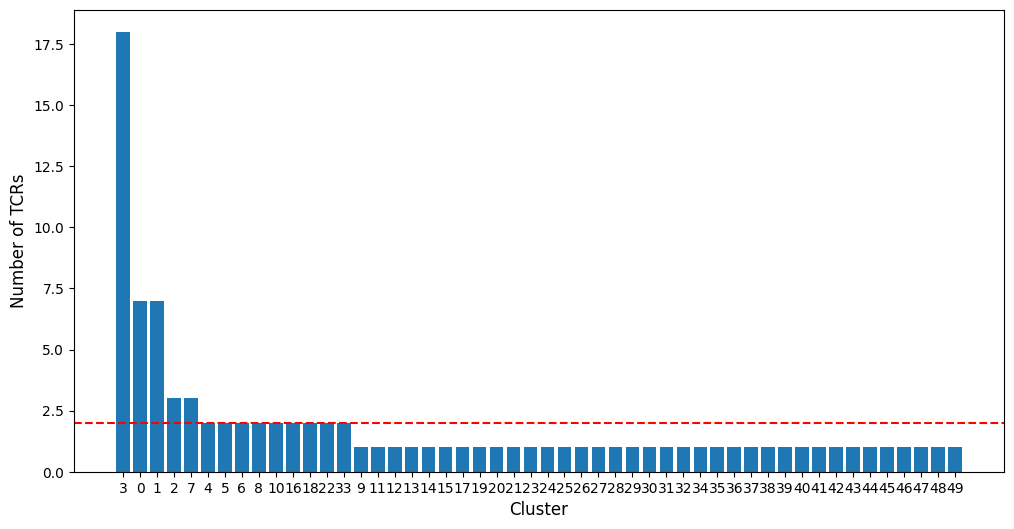

In [15]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(2, color='red', linestyle='--')

plt.show()

In [16]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [17]:
dash_bmlf['cluster'] = clusters_filtered
dash_bmlf['cluster'] = dash_bmlf['cluster'].astype(str)
dash_bmlf['cluster'] = dash_bmlf['cluster'].replace('-1', 'None')

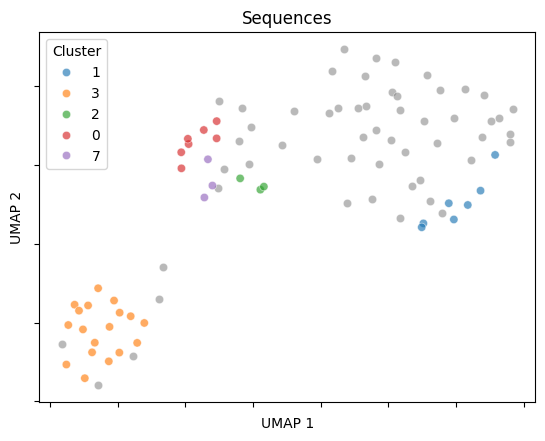

In [18]:
plot_umap(umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix), dash_bmlf['cluster'], title='Sequences')
plt.show()

## Structure Prediction Features

In [19]:
def is_constant(column: pd.Series) -> bool:
    return (column == column.iloc[0]).all()


def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    return df[[column_name for column_name in df.columns if not is_constant(df[column_name])]]

### Confidence Scores

In [20]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_dash_bmlf.csv')
confidence_scores['top_rank'] = False
confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [21]:
confidence_scores = confidence_scores.merge(dash_bmlf, how='left', left_on='name', right_on='id')

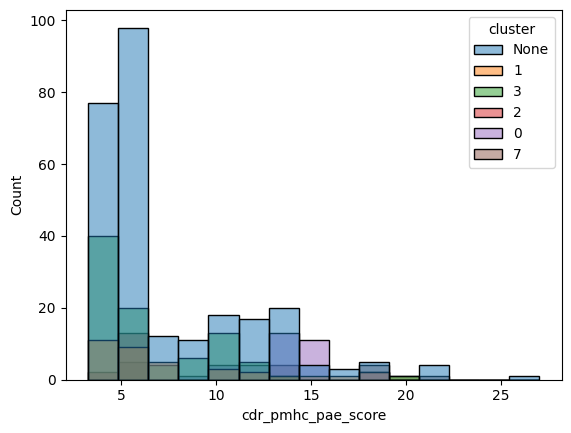

In [22]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score', hue='cluster')

plt.show()

In [23]:
confidence_scores_values = confidence_scores.select_dtypes('number')
confidence_scores_values = confidence_scores_values[
    [column_name for column_name in confidence_scores_values.columns if column_name not in ('count', 'sample', 'seed')]
]

confidence_scores_values = drop_constant_columns(confidence_scores_values)
confidence_scores_values = confidence_scores_values.to_numpy()

In [24]:
confidence_scores_values_norm = StandardScaler().fit_transform(confidence_scores_values)
confidence_scores_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(confidence_scores_values_norm)

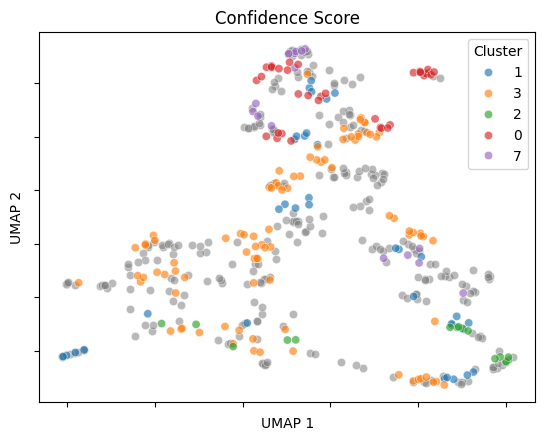

In [25]:
plot_umap(confidence_scores_umap, confidence_scores['cluster'].to_numpy(), title='Confidence Score')
plt.show()

### Structural Features

In [26]:
structure_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_dash_bmlf.csv')

In [27]:
structure_features = structure_features.merge(dash_bmlf, how='outer', left_on='name', right_on='id')

In [28]:
structure_features_values = structure_features.select_dtypes('number')
structure_features_values = structure_features_values[
    [column_name for column_name in structure_features_values.columns if column_name not in ('count', 'sample', 'seed')]
]


structure_features_values = drop_constant_columns(structure_features_values)
structure_features_values = structure_features_values.to_numpy()

In [29]:
structure_features_values_norm = StandardScaler().fit_transform(structure_features_values)
structure_features_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(structure_features_values_norm)

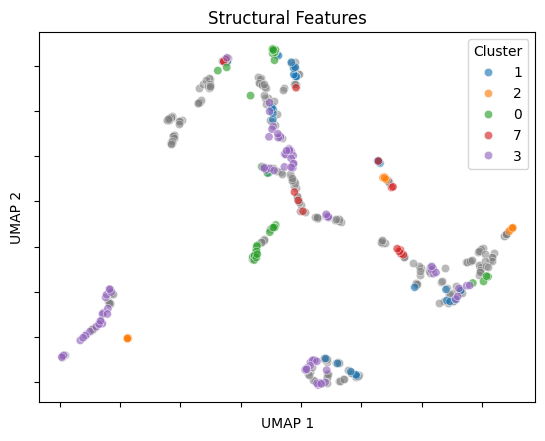

In [30]:
plot_umap(structure_features_umap, structure_features['cluster'].to_numpy(), title='Structural Features')
plt.show()

#### Contact Maps

In [31]:
contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_dash_bmlf.csv')

In [32]:
contact_maps['relative_pos_centre_tcr'] = contact_maps['relative_pos_centre_tcr'].astype(int)

In [33]:
contact_maps['resi_pmhc'] = contact_maps['resi_pmhc'].str.replace('.0', '')

In [34]:
contact_maps['chain_type_pmhc'].unique()

array(['mhc_chain1', 'antigen_chain'], dtype=object)

In [35]:
contact_maps_antigens = contact_maps[contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [36]:
contact_maps_antigens['relative_pos_centre_pmhc'] = contact_maps_antigens['relative_pos_centre_pmhc'].astype(int)

In [37]:
contact_map_antigens_scores = (
    contact_maps_antigens.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_antigens_scores.columns.to_flat_index()
]

In [38]:
contact_maps_mhc = contact_maps[contact_maps['chain_type_pmhc'] == 'mhc_chain1'].copy()

In [39]:
contact_map_mhc_scores = (
    contact_maps_mhc.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_mhc_scores.columns.to_flat_index()
]

In [40]:
contact_map_scores = pd.concat([contact_map_antigens_scores, contact_map_mhc_scores], axis=1).fillna(0).map(int)
contact_map_scores = drop_constant_columns(contact_map_scores)
contact_map_column_names = contact_map_scores.columns

In [41]:
contact_map_scores = contact_map_scores.reset_index().merge(dash_bmlf, how='outer', left_on='name', right_on='id')

In [42]:
contact_map_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(contact_map_scores[contact_map_column_names])

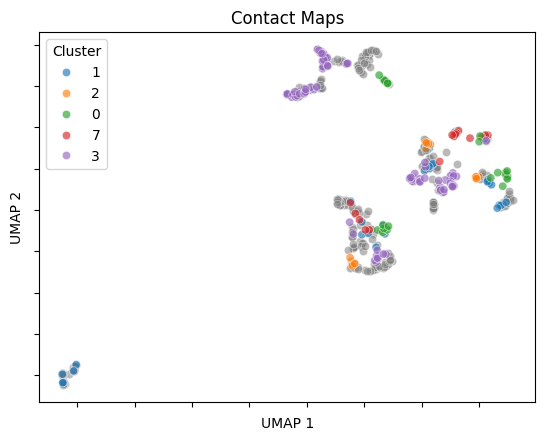

In [43]:
plot_umap(contact_map_umap, contact_map_scores['cluster'].to_numpy(), title='Contact Maps')
plt.show()

#### Interactions

In [44]:
interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_dash_bmlf.csv')

In [45]:
interactions_scores = (
    interactions.groupby(['name', 'seed', 'sample'])['type']
    .value_counts()
    .reset_index()
    .pivot_table(index=['name', 'seed', 'sample'], columns='type', values='count')
    .fillna(0)
    .map(int)
)
interactions_scores_column_names = interactions_scores.columns

interactions_scores = interactions_scores.reset_index().merge(dash_bmlf, how='outer', left_on='name', right_on='id')
interactions_scores = interactions_scores.fillna(0)

In [46]:
interactions_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    interactions_scores[interactions_scores_column_names]
)

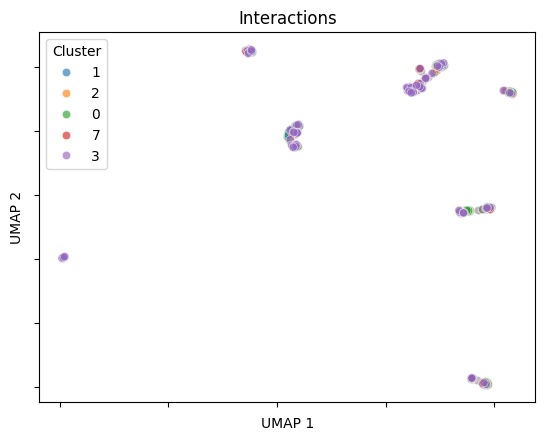

In [47]:
plot_umap(interactions_umap, interactions_scores['cluster'].to_numpy(), title='Interactions')
plt.show()

#### Combined

In [48]:
combined_scores = (
    structure_features.merge(contact_map_scores, how='outer').merge(interactions_scores, how='outer').fillna(0.0)
)

In [49]:
combined_scores_values = combined_scores.select_dtypes('number')
combined_scores_values = combined_scores_values[
    [column_name for column_name in combined_scores_values.columns if column_name not in ('count', 'sample', 'seed')]
]
combined_scores_values = combined_scores_values.to_numpy()

In [50]:
combined_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(combined_scores_values)

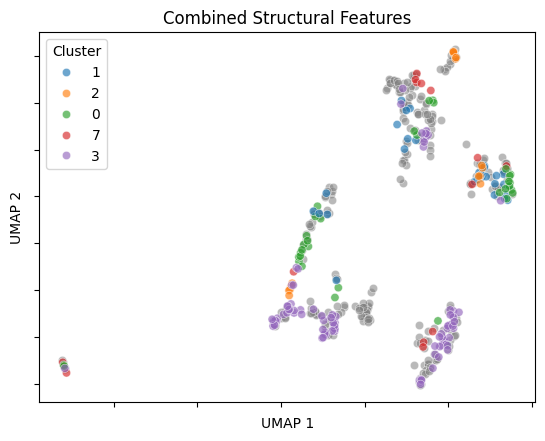

In [51]:
plot_umap(combined_umap, combined_scores['cluster'].to_numpy(), title='Combined Structural Features')
plt.show()